# Entropy Calculation

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
from qss.entropy import entropy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot as sp


## 2D Lattice

In [11]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Entropy

In [12]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])

    if "entropy" in mu_df.columns:
        entropy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        entropy_df = entropy(mu_df, e_k)
        entropy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
entropy_df

mu  iterations  converged  \
distro n        k_BT    H_a                                         
FD     0.010000 100.000 0.0    -529.341704          23       True   
       0.035128 100.000 0.0    -402.428638          19       True   
       0.060256 100.000 0.0    -347.180857          22       True   
       0.085385 100.000 0.0    -311.020926          23       True   
       0.110513 100.000 0.0    -283.902851          23       True   
...                                    ...         ...        ...   
NFLB   0.889487 0.001   1000.0   -0.152014          24       True   
       0.914615 0.001   1000.0   -0.119698          25       True   
       0.939744 0.001   1000.0   -0.073527          26       True   
       0.964872 0.001   1000.0   -0.054175          28       True   
       0.990000 0.001   1000.0   -0.015461          31       True   

                                    residual   entropy  
distro n        k_BT    H_a                             
FD     0.010000 100.000 0.0     8.402876e-09  0.062957  
       0.035128 100.000 0.0     2.548343e-09  0.176799  
       0.060256 100.000 0.0     4.310353e-08  0.270369  
       0.085385 100.000 0.0     2.215283e-08  0.352808  
       0.110513 100.000 0.0     7.945640e-08  0.427411  
...                                      ...       ...  
NFLB   0.889487 0.001   1000.0  4.170082e-08  0.620078  
       0.914615 0.001   1000.0  6.780604e-09  0.631005  
       0.939744 0.001   1000.0  8.969100e-09  0.656755  
       0.964872 0.001   1000.0  1.171193e-08  0.665793  
       0.990000 0.001   1000.0  3.305606e-09  0.687247  

[6000 rows x 5 columns]

#### $\frac{S} {k_B N} = f(n)$

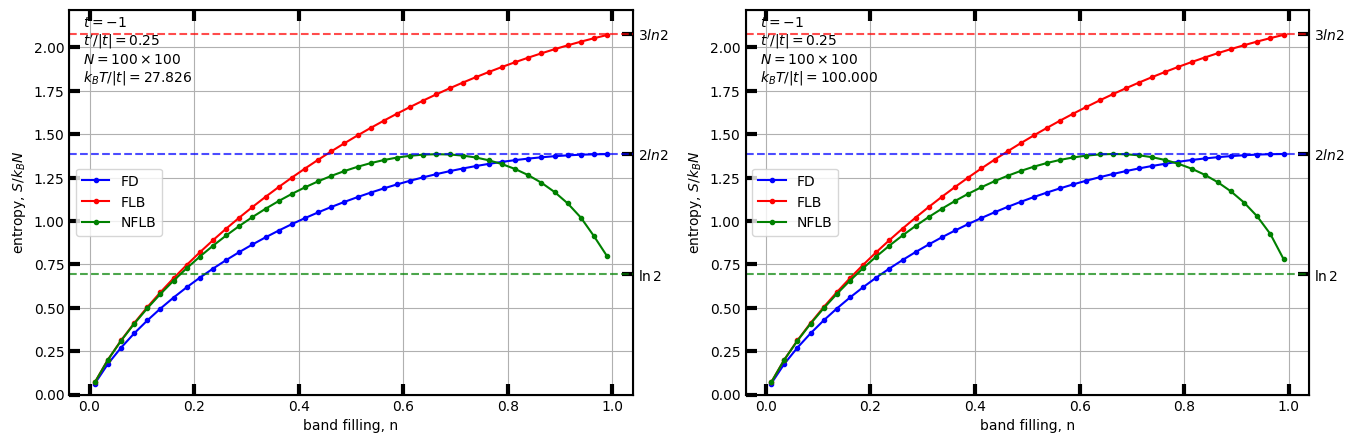

In [18]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=entropy_df,
    n=n,
    betas=beta_plot,
    y_label=r"entropy, $S / k_B N$",
    distros=[DistType.FD, DistType.FLB, DistType.NFLB],
    H_a=H_a_plot,
    y_col="entropy",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2, # Adjust columns for layout
    show_log_vals=True
)
plt.show()

### $\frac{S} {k_B N} = f(k_BT)$


<Figure size 640x480 with 0 Axes>

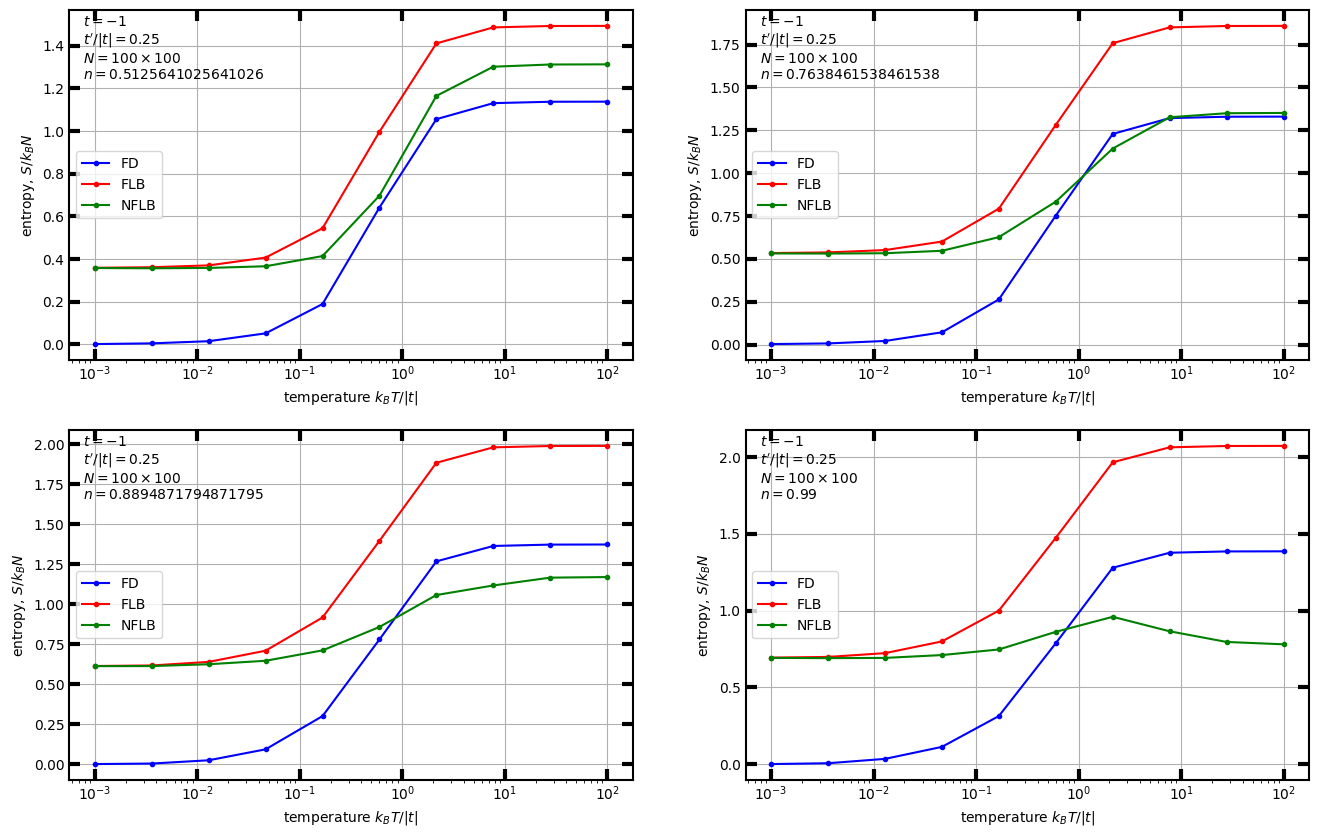

In [14]:
n_plot = [n[20], n[30], n[-5], n[-1]]
H_a_plot = H_a[0]

# Plotimport scientific_plot as sp
sp.plot_results_temperature(
    results=entropy_df,
    n=n_plot,
    betas=1/k_BT,
    y_label=r"entropy, $S / k_B N$",
    distros=[DistType.FD, DistType.FLB, DistType.NFLB],
    H_a=H_a_plot,
    y_col="entropy",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
)
plt.show()

#### $\frac{S} {k_B N} = f(H_a)$

<Figure size 640x480 with 0 Axes>

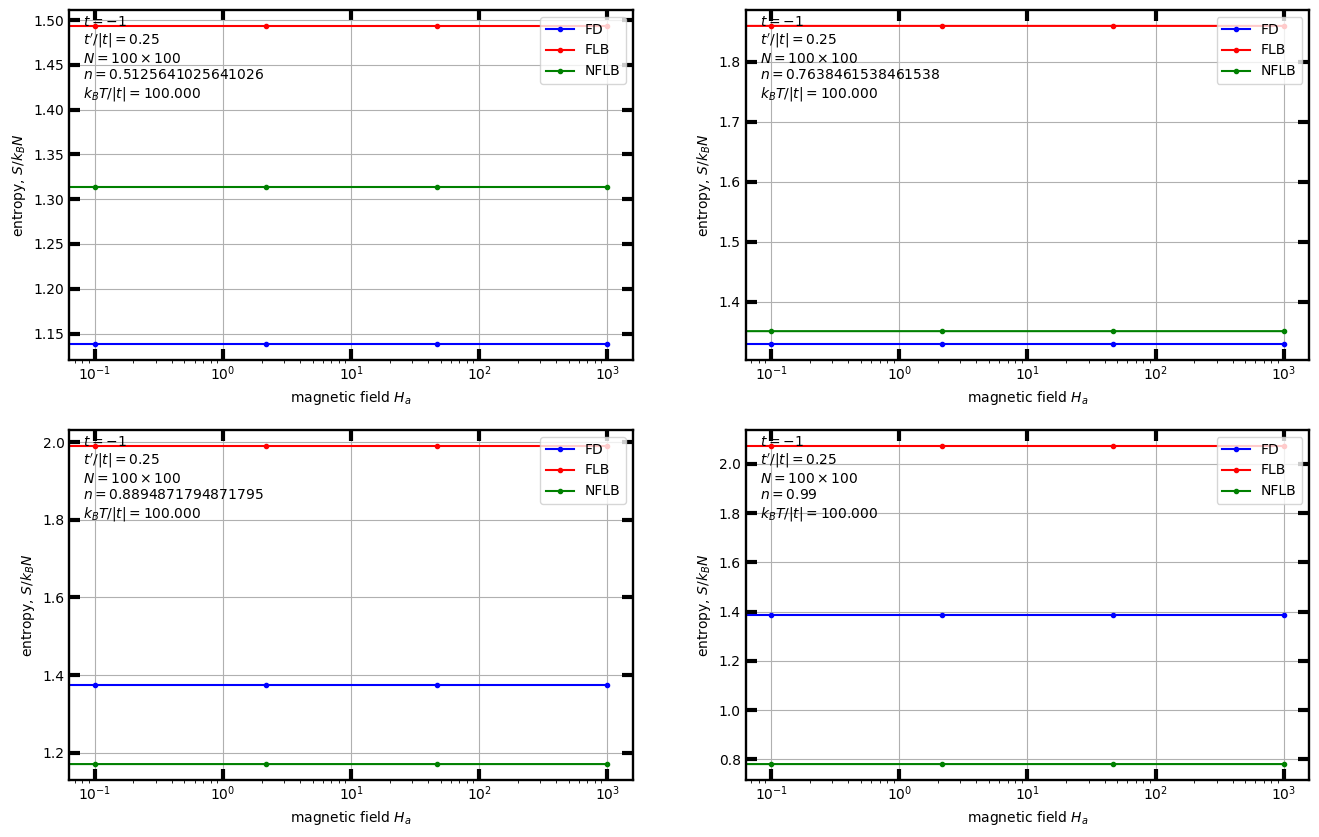

In [15]:
n_plot = [n[20], n[30], n[-5], n[-1]]
beta_plot = 1/k_BT[-1]
sp.plot_results_Ha(
    results=entropy_df,
    n=n_plot,          # List of n values to create subplots for
    beta=beta_plot,     # Fixed beta value
    y_label=r"entropy, $S / k_B N$",
    distros=[DistType.FD, DistType.FLB, DistType.NFLB],
    y_col="entropy",
    legend_position="upper right",
    figsize=(8, 5),
    cols=2
)
plt.show()

#### $\frac{S} {k_B N} = f(n, k_BT)$

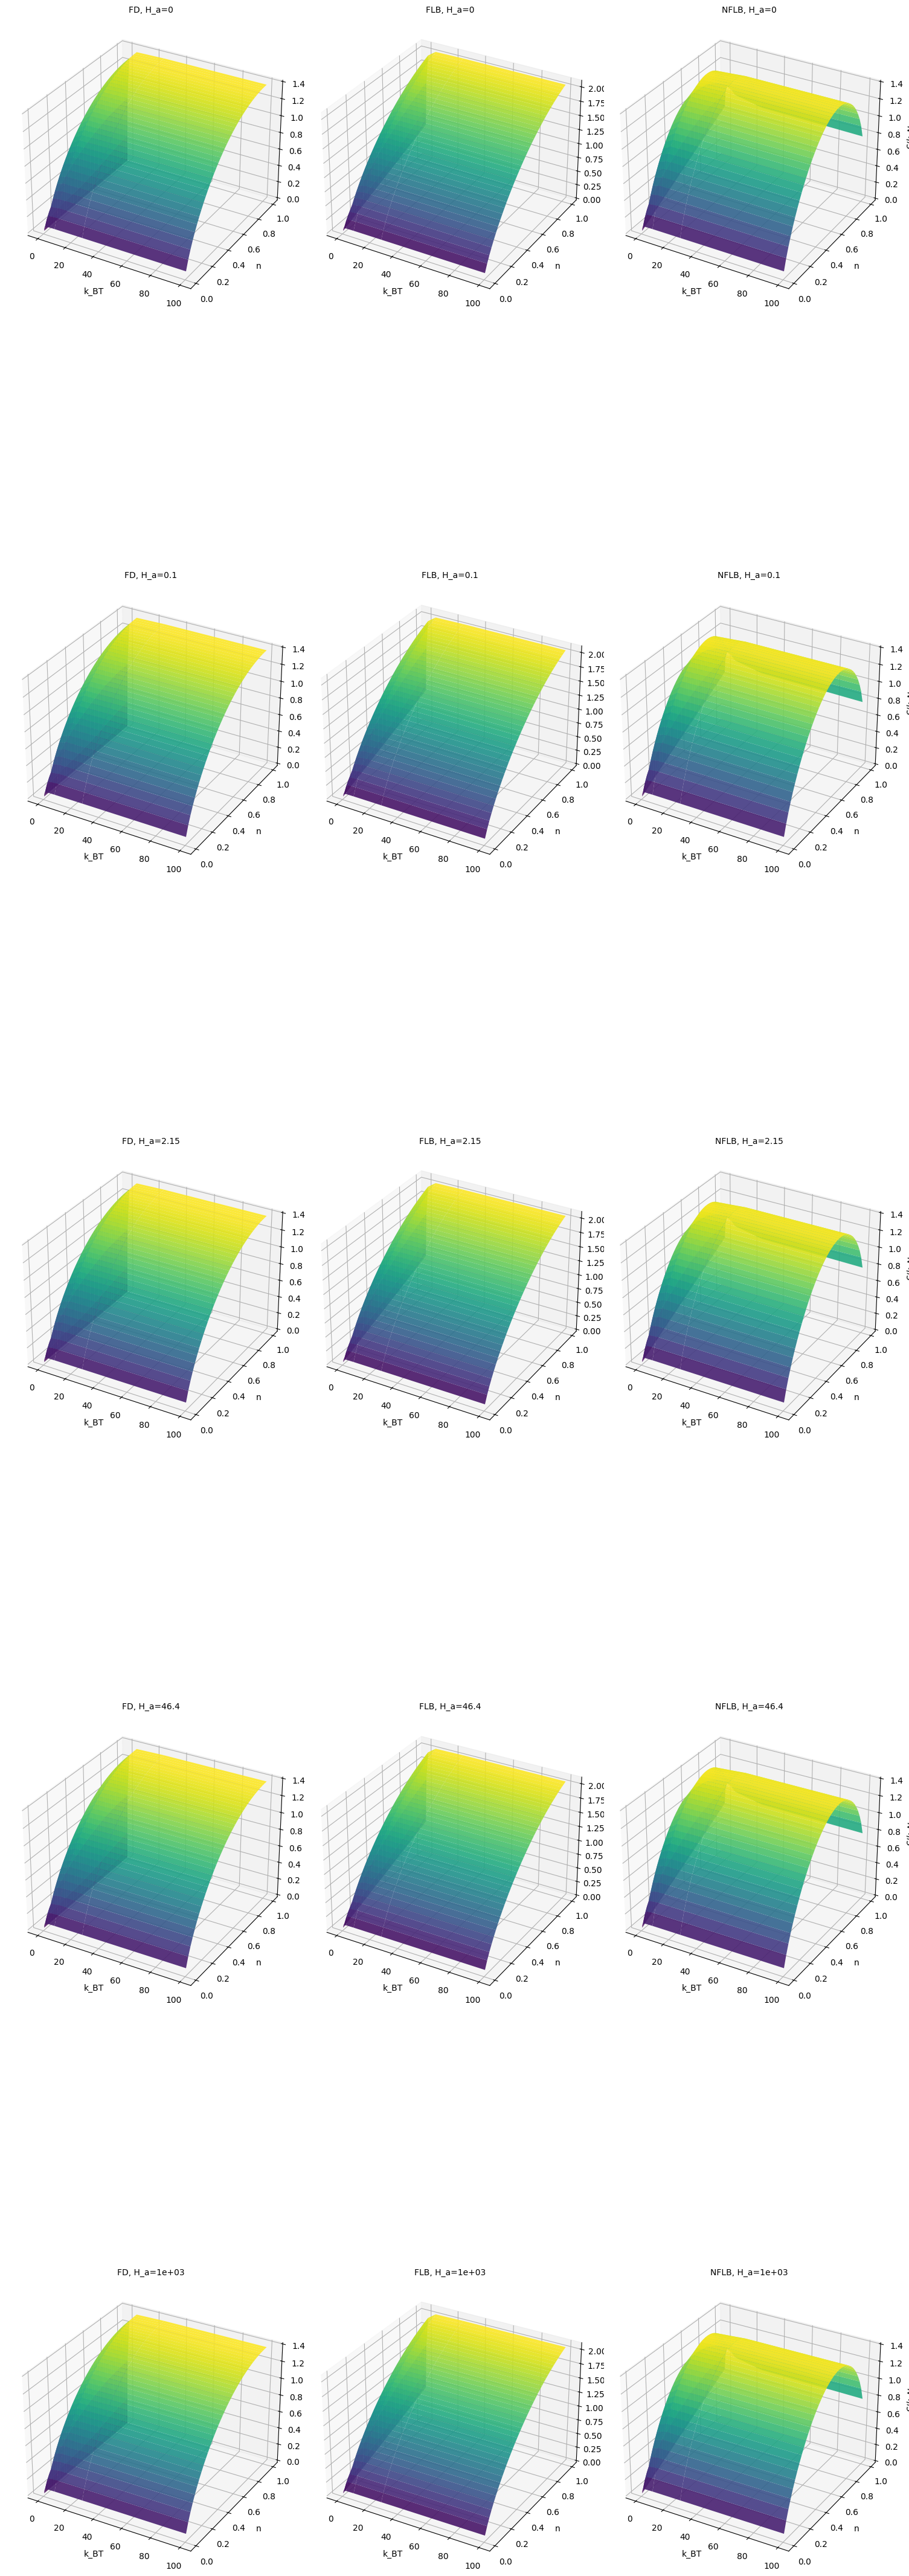

In [16]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
sp.plot_3d_results(
    results=entropy_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a,     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="entropy",          # or "entropy" if you have calculated it
    distros=[DistType.FD, DistType.FLB, DistType.NFLB],
    figsize=(15, 10)
)
plt.show()